# Лабораторная работа 3

Запуск локальный на Apple M2 Max через MPS

Для BERT-частей используется компактный русский cointegrated/rubert-tiny2

Для генерации ai-forever/rugpt3small_based_on_gpt2

In [17]:
import json, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.nn.functional import softmax
from torch.utils.data import DataLoader
from datasets import load_dataset, Dataset
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM, AutoModelForCausalLM, AutoModelForSequenceClassification

np.random.seed(42)
torch.manual_seed(42)
device = torch.device('mps')


## 1. Self-attention вручную

In [2]:
words = ['я', 'люблю', 'обработку', 'текста']
emb = np.random.normal(0, .5, (4, 8))
Wq = np.random.normal(0, .5, (8, 8))
Wk = np.random.normal(0, .5, (8, 8))
Wv = np.random.normal(0, .5, (8, 8))

Q, K, V = emb @ Wq, emb @ Wk, emb @ Wv
scores = Q @ K.T / np.sqrt(8)
weights = np.exp(scores - scores.max(axis=1, keepdims=True))
weights /= weights.sum(axis=1, keepdims=True)
attention = weights @ V

print('Веса внимания:')
display(pd.DataFrame(weights, index=words, columns=words).round(3))
print('Итоговые векторы:')
display(pd.DataFrame(attention, index=words).round(3))

Веса внимания:


,я,люблю,обработку,текста
я,0.164,0.341,0.220,0.275
люблю,0.284,0.162,0.205,0.349
обработку,0.372,0.201,0.263,0.164
текста,0.203,0.306,0.237,0.254


Итоговые векторы:


,0,1,2,3,4,5,6,7
я,-0.051,-1.014,-0.463,-0.676,0.021,0.203,0.048,-0.560
люблю,-0.081,-0.382,-0.277,-0.422,0.238,-0.097,0.066,-0.427
обработку,0.008,-0.166,-0.210,-0.252,0.095,0.109,-0.053,-0.248
текста,-0.033,-0.844,-0.410,-0.588,0.026,0.193,0.029,-0.501


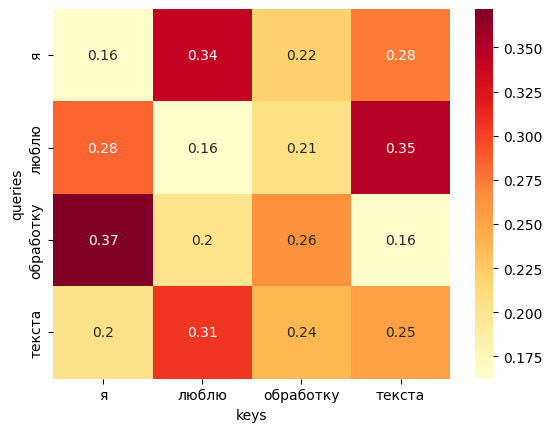

Больше всего суммарного внимания получил токен: текста


In [3]:
sns.heatmap(weights, annot=True, cmap='YlOrRd', xticklabels=words, yticklabels=words)
plt.xlabel('keys')
plt.ylabel('queries')
plt.show()

received = weights.sum(axis=0)
print('Больше всего суммарного внимания получил токен:', words[received.argmax()])

Токен "текста" нельзя нормально воспринимать как смысл, так как эмбеддинги и матрицы весов заданы случайно, поэтому этот результат не имеет содержательной связи со смыслом предложения

При большой размерности скалярные произведения могут получиться слишком большими. Тогда softmax становится слишком резким, у него почти вся вероятность достаётся одному токену, а остальные веса становятся близки к нулю. Деление на $\sqrt{d_k}$ может уменьшить этот эффект.

## 2. Предобученные модели

In [4]:
bert_name = 'cointegrated/rubert-tiny2'
tokenizer = AutoTokenizer.from_pretrained(bert_name)

sentences = [
    'Сегодня во Владивостоке хорошая погода.',
    'Нейросетевые модели умеют работать с текстом.',
    'Я перечитал «Преступление и наказание».',
    'Микроэлектроника развивается очень быстро.',
    'Предобученный трансформер разбивает слова на части.',
    'Кот неожиданно запрыгнул на подоконник.'
]
for s in sentences:
    print(s)
    print(tokenizer.tokenize(s), '\n')

Сегодня во Владивостоке хорошая погода.
['Сегодня', 'во', 'Владивостоке', 'хорошая', 'погода', '.'] 

Нейросетевые модели умеют работать с текстом.
['Ней', '##рос', '##ете', '##вые', 'модели', 'умеют', 'работать', 'с', 'текстом', '.'] 

Я перечитал «Преступление и наказание».
['Я', 'перечи', '##тал', '«', 'Преступ', '##ление', 'и', 'наказание', '»', '.'] 

Микроэлектроника развивается очень быстро.
['Микро', '##электрон', '##ика', 'развивается', 'очень', 'быстро', '.'] 

Предобученный трансформер разбивает слова на части.
['Пред', '##обу', '##ченный', 'транс', '##форм', '##ер', 'разбивает', 'слова', 'на', 'части', '.'] 

Кот неожиданно запрыгнул на подоконник.
['Кот', 'неожиданно', 'запрыг', '##нул', 'на', 'подоко', '##нник', '.'] 



Редкие и длинные слова разбиваются на субтокены, потому что держать в словаре все формы слоав невозможно. Модель получает ограниченный словарь и всё равно может обработать почти любое новое слово.

In [5]:
mlm = AutoModelForMaskedLM.from_pretrained(bert_name).to(device).eval()
mask_sentences = [
    'Столица России — [MASK].',
    'Зимой на улице идёт [MASK].',
    'Кошка поймала серую [MASK].',
    'Для программы я написал [MASK] на Python.',
    'Врач выписал пациенту [MASK].',
    'После дождя на небе появилась [MASK].'
]
with torch.no_grad():
    for s in mask_sentences:
        batch = tokenizer(s, return_tensors='pt').to(device)
        pos = (batch.input_ids[0] == tokenizer.mask_token_id).nonzero()[0].item()
        logits = mlm(**batch).logits[0, pos]
        ids = logits.topk(5).indices.cpu().tolist()
        print(s, '->', tokenizer.convert_ids_to_tokens(ids))

Столица России — [MASK]. -> ['Москва', 'Украина', 'Россия', 'Турция', 'Германия']
Зимой на улице идёт [MASK]. -> ['дорога', 'речь', 'улица', 'снег', 'остановка']
Кошка поймала серую [MASK]. -> ['собаку', 'руку', 'девушку', 'рыбу', 'воду']
Для программы я написал [MASK] на Python. -> ['ссылку', 'книгу', 'статью', 'программу', 'сценарий']
Врач выписал пациенту [MASK]. -> ['врача', 'пациенту', 'врач', 'самостоятельно', 'диагноз']
После дождя на небе появилась [MASK]. -> ['погода', 'вода', 'молния', 'новая', 'звезда']


Хороший результат получился для предложения про столицу России. В остальных примерах модель часто выбирала грамматически нормальные, но неподходящие по смыслу слова. Самый плохой результат по моему мнению с дождём, очевидно должно быть что радуга

Скорее всего небольшой модели не всегда хватает контекста для точного ответа

In [6]:
gpt_name = 'ai-forever/rugpt3small_based_on_gpt2'
gpt_tok = AutoTokenizer.from_pretrained(gpt_name)
gpt = AutoModelForCausalLM.from_pretrained(gpt_name).to(device).eval()
gpt_tok.pad_token = gpt_tok.eos_token

prompts = ['Однажды поздно вечером', 'Искусственный интеллект помогает', 'На берегу Японского моря']
settings = {
    'greedy': dict(do_sample=False),
    'top-k': dict(do_sample=True, top_k=50, temperature=.9),
    'nucleus': dict(do_sample=True, top_p=.9, temperature=.9)
}
for prompt in prompts:
    print('\nPROMPT:', prompt)
    x = gpt_tok(prompt, return_tensors='pt').to(device)
    for name, params in settings.items():
        torch.manual_seed(42)
        with torch.no_grad():
            out = gpt.generate(**x, max_new_tokens=45, pad_token_id=gpt_tok.eos_token_id, **params)
        print(name, ':', gpt_tok.decode(out[0], skip_special_tokens=True))


PROMPT: Однажды поздно вечером
greedy : Однажды поздно вечером, когда я уже собирался уходить, в дверь позвонили.

— Кто там? — спросил я.

— Это я, — ответил голос.

— Кто это?

—
top-k : Однажды поздно вечером в дом к ней в гости пришел молодой человек, на вид лет двадцати пяти, с длинными волосами русой растительности, одетый в темно-серое трико… Это был ее любимый, а теперь у нее был только один
nucleus : Однажды поздно вечером в дом к ней влетел взъерошенный, взъерошенный и взъерошенный кот.

— Привет! — сказала она.

— Привет, — отозвался он.

Она увидела

PROMPT: Искусственный интеллект помогает
greedy : Искусственный интеллект помогает нам в решении самых сложных задач.  Мы можем создавать и улучшать наши проекты, а также создавать новые.  Мы можем создавать и улучшать наши проекты.  Мы можем создавать и улучшать наши проекты.  Мы можем
top-k : Искусственный интеллект помогает нам, людям, в поисках мудрости.
М.А.Тарасов


В своей книге М.А.Тарасов раскрывает множество интересн

Greedy всегда выбирает наиболее вероятный следующий токен, поэтому результат получается предсказуемым, но иногда зацикливается или уходит не туда. Top-k и nucleus дают более разнообразный текст, но добавляют повторы и выдуманные факты. В этих примерах наиболее связным получился top-k, а nucleus чаще выдавал повторы, странные числа и посторонние фрагменты.

### Контекстные эмбеддинги слова «ключ»

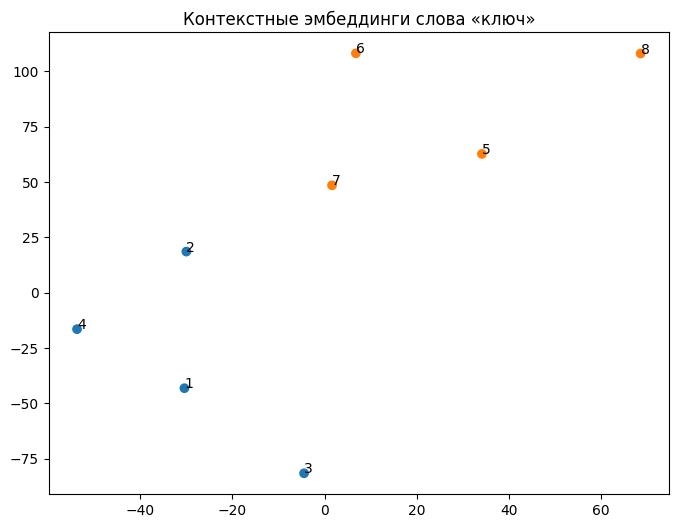

1 Я потерял ключ от входной двери.
2 Мастер сделал новый ключ для замка.
3 Ключ от машины лежал на столе.
4 Она повернула ключ в замке.
5 Из-под горы бил холодный ключ.
6 Мы набрали воду из лесного ключа.
7 Рядом с деревней нашли чистый ключ.
8 Вода в горном ключе была очень холодной.


In [9]:
encoder = AutoModel.from_pretrained(bert_name).to(device).eval()
bank_sentences = [
    'Я потерял ключ от входной двери.',
    'Мастер сделал новый ключ для замка.',
    'Ключ от машины лежал на столе.','Она повернула ключ в замке.',
    'Из-под горы бил холодный ключ.',
    'Мы набрали воду из лесного ключа.',
    'Рядом с деревней нашли чистый ключ.',
    'Вода в горном ключе была очень холодной.'
]

context_vecs = []
for s in bank_sentences:
    enc = tokenizer(s, return_offsets_mapping=True, return_tensors='pt')
    offsets = enc.pop('offset_mapping')[0].tolist()
    start = s.lower().find('ключ')
    ids = [i for i, (a, b) in enumerate(offsets) if a < start + 4 and b > start]
    enc = enc.to(device)
    with torch.no_grad():
        hidden = encoder(**enc).last_hidden_state[0, ids].mean(0)
    context_vecs.append(hidden.cpu().numpy())

xy = TSNE(n_components=2, perplexity=3, init='pca', learning_rate='auto',
          random_state=42).fit_transform(np.array(context_vecs))
colors = ['tab:blue'] * 4 + ['tab:orange'] * 4
plt.figure(figsize=(8, 6))
plt.scatter(xy[:,0], xy[:,1], c=colors)
for i, p in enumerate(xy): plt.annotate(str(i + 1), p)
plt.title('Контекстные эмбеддинги слова «ключ»')
plt.show()
for i, s in enumerate(bank_sentences): print(i + 1, s)

Контекстные эмбеддинги разделились по значениям слова, ключ от замка и природный источник. При этом точные расстояния интерпретировать не получится, t-SNE на восьми точках работает нестабильно

## 3. Fine-tuning RuBERT

In [18]:
raw = load_dataset('MonoHime/ru_sentiment_dataset', split='train').to_pandas()[['text', 'sentiment']]
raw = raw.dropna().drop_duplicates('text')
raw = pd.concat([group.sample(2500, random_state=42)for _, group in raw.groupby('sentiment')])
raw = raw.sample(frac=1, random_state=42).reset_index(drop=True)

train_pd, test_pd = train_test_split(raw, test_size=0.2, random_state=42, stratify=raw['sentiment'])

train_pd, val_pd = train_test_split(train_pd, test_size=0.15, random_state=42, stratify=train_pd['sentiment'])

print('train:', len(train_pd))
print('validation:', len(val_pd))
print('test:', len(test_pd))

train: 5100
validation: 900
test: 1500


In [19]:
from torch.utils.data import TensorDataset, DataLoader

train_tokens = tokenizer(
    train_pd['text'].tolist(),
    truncation=True,
    padding='max_length',
    max_length=128,
    return_tensors='pt'
)

val_tokens = tokenizer(
    val_pd['text'].tolist(),
    truncation=True,
    padding='max_length',
    max_length=128,
    return_tensors='pt'
)

test_tokens = tokenizer(
    test_pd['text'].tolist(),
    truncation=True,
    padding='max_length',
    max_length=128,
    return_tensors='pt'
)

train_data = TensorDataset(
    train_tokens['input_ids'],
    train_tokens['attention_mask'],
    torch.tensor(train_pd['sentiment'].to_numpy())
)

val_data = TensorDataset(
    val_tokens['input_ids'],
    val_tokens['attention_mask'],
    torch.tensor(val_pd['sentiment'].to_numpy())
)

test_data = TensorDataset(
    test_tokens['input_ids'],
    test_tokens['attention_mask'],
    torch.tensor(test_pd['sentiment'].to_numpy())
)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

In [21]:
clf = AutoModelForSequenceClassification.from_pretrained(bert_name, num_labels=3).to(device)

optimizer = torch.optim.AdamW(clf.parameters(), lr=2e-5)

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(3):
    clf.train()

    total_loss = 0

    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        output = clf(input_ids=input_ids, attention_mask=attention_mask,labels=labels)

        output.loss.backward()
        optimizer.step()

        total_loss += output.loss.item() * len(labels)

    train_loss = total_loss / len(train_data)
    train_losses.append(train_loss)

    clf.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            output = clf(input_ids=input_ids, attention_mask=attention_mask, labels=labels)

            total_loss += output.loss.item() * len(labels)

            predictions = output.logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += len(labels)

    val_loss = total_loss / len(val_data)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        epoch + 1,
        'train loss:', round(train_loss, 4),
        'val loss:', round(val_loss, 4),
        'val accuracy:', round(val_accuracy, 4)
    )

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at cointegrated/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


1 train loss: 0.8877 val loss: 0.7533 val accuracy: 0.6489
2 train loss: 0.658 val loss: 0.6773 val accuracy: 0.6844
3 train loss: 0.5384 val loss: 0.6746 val accuracy: 0.6822


Test accuracy: 0.718
Test F1: 0.7149


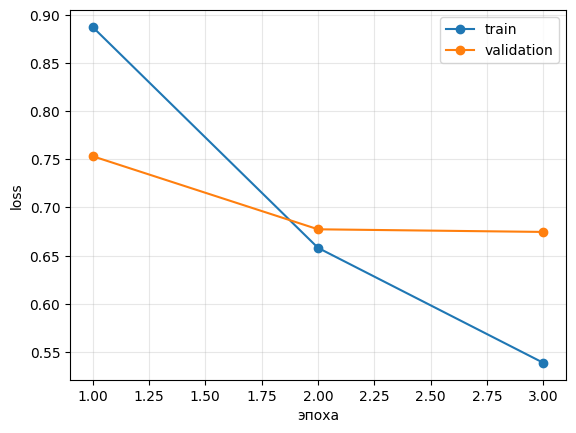

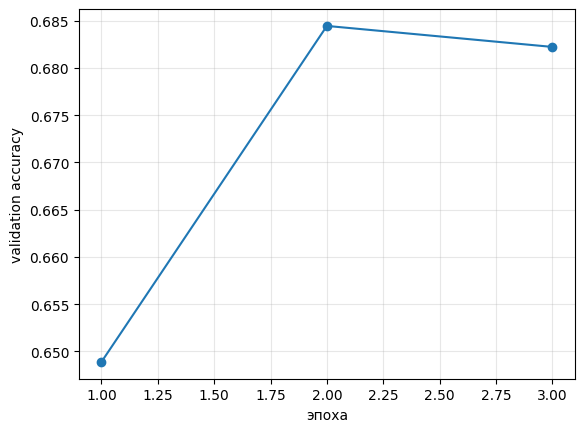

In [22]:
clf.eval()

true = []
pred = []

with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        output = clf(input_ids=input_ids, attention_mask=attention_mask)

        predictions = output.logits.argmax(dim=1).cpu().numpy()

        pred.extend(predictions)
        true.extend(labels.numpy())

bert_acc = accuracy_score(true, pred)
bert_f1 = f1_score(true, pred, average='weighted')

print('Test accuracy:', round(bert_acc, 4))
print('Test F1:', round(bert_f1, 4))

plt.plot(range(1, 4), train_losses, 'o-', label='train')
plt.plot(range(1, 4), val_losses, 'o-', label='validation')
plt.xlabel('эпоха')
plt.ylabel('loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.plot(range(1, 4), val_accuracies, 'o-')
plt.xlabel('эпоха')
plt.ylabel('validation accuracy')
plt.grid(alpha=0.3)
plt.show()

In [24]:
table = [
    ['Логистическая регрессия (TF-IDF)', 0.718],
    ['Нейросеть + Navec', 0.7033],
    ['Fine-tuned RuBERT', bert_acc]
]

display(pd.DataFrame(table, columns=['Метод', 'Test Accuracy']))

,Метод,Test Accuracy
0,Логистическая регрессия (TF-IDF),0.7180
1,Нейросеть + Navec,0.7033
2,Fine-tuned RuBERT,0.7180


Все три метода дали близкие результаты. Большого прироста после перехода к RuBERT в этой лабораторной не получилось, при этом он обучается дольше и требует больше памяти. К третьей эпохе у RuBERT появилось небольшое переобучение, train loss продолжил уменьшаться, а validation accuracy немного снизилась

Для такой задачи TF-IDF получился самым выгодным вариантом. Трансформер полезнее, когда для классификации особенно важны контекст и порядок слов